In [24]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans,DBSCAN,HDBSCAN 
from sklearn.preprocessing import StandardScaler 
from openTSNE import TSNE 
from sklearn.decomposition import PCA 
from sklearn.preprocessing import LabelEncoder 
from collections import Counter 
import hdbscan 

np.set_printoptions(legacy='1.25')


In [2]:
wdf = pd.read_csv('allwellslith2.csv')
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3


In [48]:
Counter(wdf.iloc[:,-2])

Counter({'Mudstone': 208687,
         'Limestone': 16734,
         'Shaly_Sand': 6966,
         'Dolomite': 3395,
         'Shale': 1925,
         'Clean_Sand': 740})

In [6]:
X = wdf.iloc[:,:-3].values
Xssc = StandardScaler().fit_transform(X)
Xssc.shape

(238447, 7)

In [7]:
clusterer2 = hdbscan.HDBSCAN(min_cluster_size=500,
                            min_samples=500).fit(Xssc)



In [12]:
wdf['DBS500'] = clusterer2.labels_
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,11
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,11
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,11
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,11
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,11


In [13]:
Counter(wdf.DBS500)

Counter({-1: 152895,
         11: 49966,
         5: 8517,
         9: 7379,
         10: 6047,
         3: 3793,
         8: 2490,
         7: 2225,
         4: 1401,
         1: 1294,
         6: 1191,
         0: 708,
         2: 541})

In [14]:
Counter(wdf.iloc[:,-3])

Counter({'Mudstone': 208687,
         'Limestone': 16734,
         'Shaly_Sand': 6966,
         'Dolomite': 3395,
         'Shale': 1925,
         'Clean_Sand': 740})

In [20]:
def plot_cluster(X,ypred):
    for c in np.unique(ypred):
        plt.scatter(X[ypred == c,0],
                    X[ypred == c,1],
                    label = f'cluster {str(c)}',
                    s = 5,
                    alpha=0.5)
    plt.legend()

In [13]:
def plot_cluster2(X,ypred,title=None):
    for c in np.unique(ypred):
        plt.scatter(X[ypred == c,0],
                    X[ypred == c,1],
                    label = f'cluster {str(c)}',
                    s = 5,
                    alpha=0.5)
    plt.legend()
    if title:
        plt.title(title)

In [16]:
pca = PCA(n_components = 2)
Xsscpca2 = pca.fit_transform(Xssc)
Xsscpca2.shape

(238447, 2)

D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


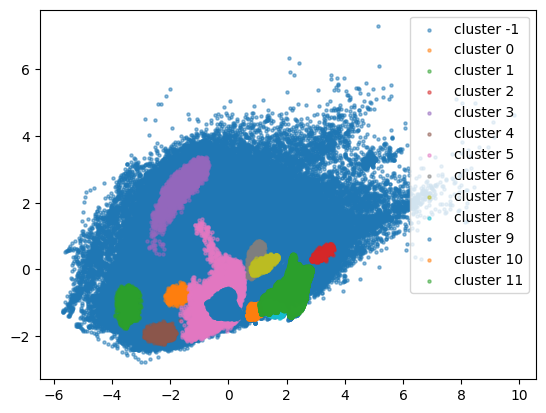

In [17]:
plot_cluster(Xsscpca2,wdf.DBS500)

In [18]:
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,11
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,11
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,11
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,11
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,11


In [19]:
wdfx = wdf[wdf.DBS500 >= 0]
wdf.shape,wdfx.shape

((238447, 11), (85552, 11))

In [20]:
X1 = wdfx.iloc[:,:-4].values
X1ssc = StandardScaler().fit_transform(X1)

pca = PCA(n_components = 2)
X1sscpca2 = pca.fit_transform(X1ssc)
X1sscpca2.shape

(85552, 2)

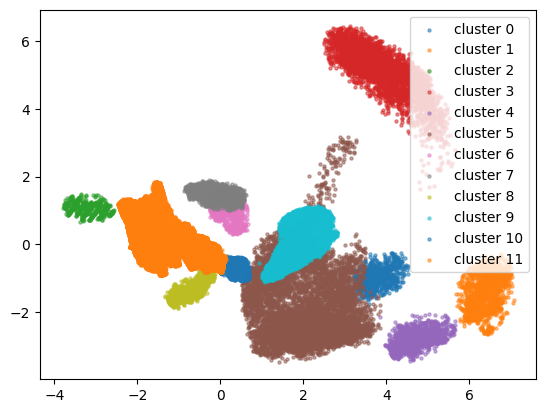

In [21]:
plot_cluster(X1sscpca2,wdfx.DBS500)

In [22]:
wdfx.to_csv('allwellsDBS500newlith.csv',index= False)

In [23]:
wdfx.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,11
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,11
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,11
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,11
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,11


## **NEW RUN**

In [49]:
dbscandf = pd.read_csv('allwellslith2.csv')
dbscandf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3


In [50]:
Counter(dbscandf.iloc[:,-2])

Counter({'Mudstone': 208687,
         'Limestone': 16734,
         'Shaly_Sand': 6966,
         'Dolomite': 3395,
         'Shale': 1925,
         'Clean_Sand': 740})

In [6]:
dbscan_xtab = pd.crosstab(index=dbscandf.iloc[:,-3],columns=dbscandf.iloc[:,-1])
dbscan_xtab

DBS500,1,2,3,4,5,6,7,8,9,10,11
LITH,,,,,,,,,,,
Limestone,0,0,2077,0,0,0,0,0,0,0,0
Mudstone,1212,541,1716,1401,8517,1191,2225,2490,7379,6047,49966
Shaly_Sand,82,0,0,0,0,0,0,0,0,0,0


In [51]:
u = pd.read_csv('umap.csv')
u.head()

,UMAP0,UMAP1
0,-4.589832,13.536960
1,-3.438218,14.166027
2,-2.903391,14.125128
3,-2.925268,14.130933
4,-3.985225,14.020511


In [32]:
u.shape, wdf.shape

((238447, 2), (238447, 11))

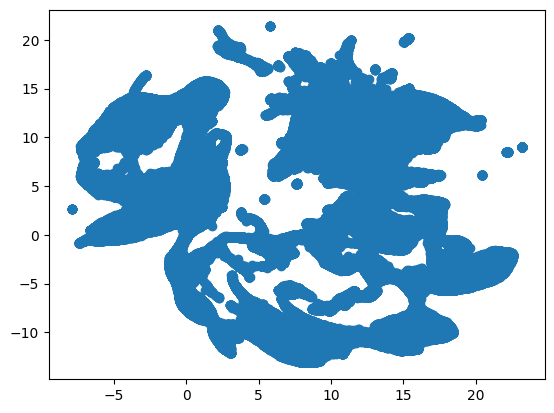

In [38]:
fig,ax = plt.subplots()
ax.scatter(u.iloc[:,0],u.iloc[:,1])

D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


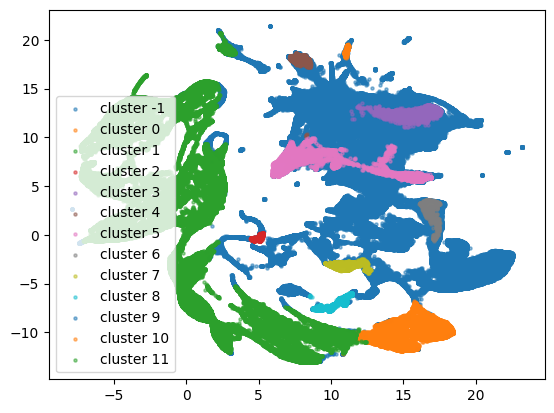

In [40]:
plot_cluster(np.array([u.iloc[:,0],u.iloc[:,1]]).T,wdf.iloc[:,-1])

In [45]:
list(range(50,1250,200))

[50, 250, 450, 650, 850, 1050]

In [ ]:
clustersizelist = list(range(50,1250,200))
minsamplelist = list(range(10,1000,200))
dbsclusterdflst  = []
for c in clustersizelist:
    for s in minsamplelist:
        print(f'{c=}   {s=}')
        clusterer = hdbscan.HDBSCAN(min_cluster_size=c,
                            min_samples=s).fit(Xssc)
        colname = f'{c}_{s}'
        clsterdf =pd.DataFrame({colname:clusterer.labels_})
        dbsclusterdflst.append(clusterer)
alldbsdf = pd.concat(dbsclusterdflst,axis=1)
alldbdf.to_csv('dbstest.csv',index=False)




In [8]:
clustersizelist = list(range(50, 1250, 200))
minsamplelist = list(range(10, 1000, 200))

dbsclusterdflst = []

for c in clustersizelist:
    for s in minsamplelist:

        print(f'c={c}, s={s}')

        # Create and fit model
        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=c,
            min_samples=s
        ).fit(Xssc)

        # Column name
        colname = f'{c}_{s}'

        # Create dataframe from labels
        clusterdf = pd.DataFrame({
            colname: clusterer.labels_
        })

        # Append DATAFRAME not clusterer
        dbsclusterdflst.append(clusterdf)

# Concatenate all dataframes
alldbsdf = pd.concat(dbsclusterdflst, axis=1)

# Save CSV
alldbsdf.to_csv('dbstest.csv', index=False)

print("CSV file saved successfully")

c=50, s=10
c=50, s=210
c=50, s=410
c=50, s=610
c=50, s=810
c=250, s=10
c=250, s=210
c=250, s=410
c=250, s=610
c=250, s=810
c=450, s=10
c=450, s=210
c=450, s=410
c=450, s=610
c=450, s=810
c=650, s=10
c=650, s=210
c=650, s=410
c=650, s=610
c=650, s=810
c=850, s=10
c=850, s=210
c=850, s=410
c=850, s=610
c=850, s=810
c=1050, s=10
c=1050, s=210
c=1050, s=410
c=1050, s=610
c=1050, s=810
CSV file saved successfully


In [9]:
alldbsdf.head()

,50_10,50_210,50_410,50_610,50_810,250_10,250_210,250_410,250_610,250_810,...,850_10,850_210,850_410,850_610,850_810,1050_10,1050_210,1050_410,1050_610,1050_810
0,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
1,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
2,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
3,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
4,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5


In [39]:
list(Counter(alldbsdf.loc[:,'850_210']))

[11, -1, 8, 5, 3, 4, 10, 9, 12, 6, 7, 1, 2, 0]

In [10]:
alldbsdf.shape

(238447, 30)

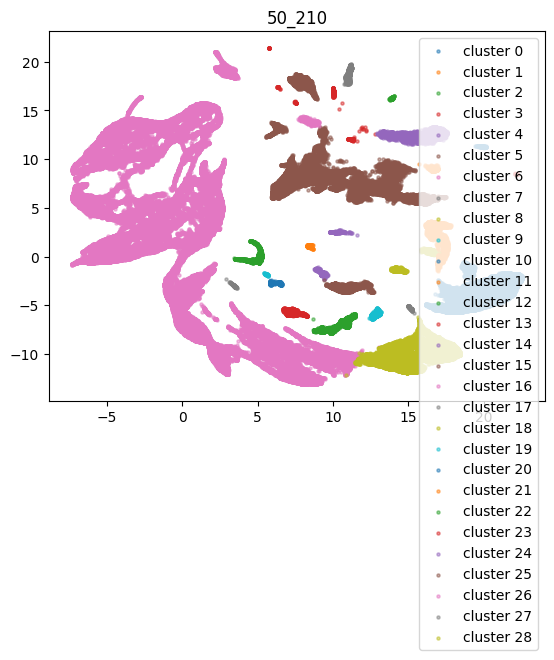

In [19]:
col2plot = 1
umapdf1 = u.copy()
umapdf1[alldbsdf.columns[col2plot]] = alldbsdf.iloc[:,col2plot]
umapdf1 = umapdf1[umapdf1.iloc[:,-1] >= 0]
plot_cluster2(np.array([umapdf1.iloc[:,0],umapdf1.iloc[:,1]]).T,umapdf1.iloc[:,-1],title=umapdf1.columns[-1])

In [22]:
alldbsdf.shape

(238447, 30)

In [23]:
for col in range(alldbsdf.shape[1]):
    c = len(Counter(alldbsdf.iloc[:,0]))
    print(f'columns {col}: {c}  Clusters')

columns 0: 135  Clusters
columns 1: 135  Clusters
columns 2: 135  Clusters
columns 3: 135  Clusters
columns 4: 135  Clusters
columns 5: 135  Clusters
columns 6: 135  Clusters
columns 7: 135  Clusters
columns 8: 135  Clusters
columns 9: 135  Clusters
columns 10: 135  Clusters
columns 11: 135  Clusters
columns 12: 135  Clusters
columns 13: 135  Clusters
columns 14: 135  Clusters
columns 15: 135  Clusters
columns 16: 135  Clusters
columns 17: 135  Clusters
columns 18: 135  Clusters
columns 19: 135  Clusters
columns 20: 135  Clusters
columns 21: 135  Clusters
columns 22: 135  Clusters
columns 23: 135  Clusters
columns 24: 135  Clusters
columns 25: 135  Clusters
columns 26: 135  Clusters
columns 27: 135  Clusters
columns 28: 135  Clusters
columns 29: 135  Clusters


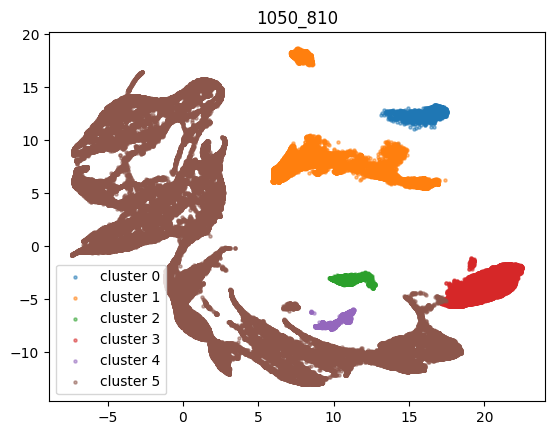

In [24]:
col2plot = 29
umapdf1 = u.copy()
umapdf1[alldbsdf.columns[col2plot]] = alldbsdf.iloc[:,col2plot]
umapdf1 = umapdf1[umapdf1.iloc[:,-1] >= 0]
plot_cluster2(np.array([umapdf1.iloc[:,0],umapdf1.iloc[:,1]]).T,umapdf1.iloc[:,-1],title=umapdf1.columns[-1])

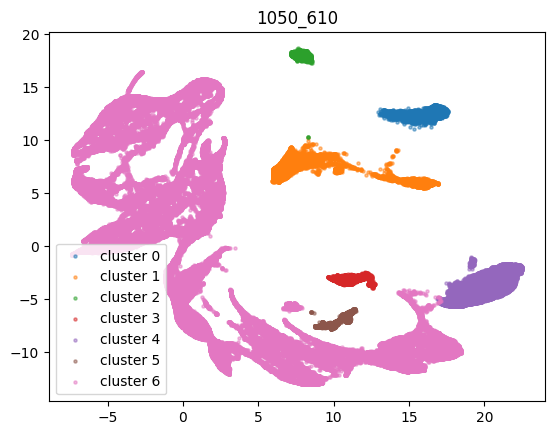

In [25]:
col2plot = 28
umapdf1 = u.copy()
umapdf1[alldbsdf.columns[col2plot]] = alldbsdf.iloc[:,col2plot]
umapdf1 = umapdf1[umapdf1.iloc[:,-1] >= 0]
plot_cluster2(np.array([umapdf1.iloc[:,0],umapdf1.iloc[:,1]]).T,umapdf1.iloc[:,-1],title=umapdf1.columns[-1])

In [32]:
dbscandf.head()

0    11
1    11
2    11
3    11
4    11
Name: DBS500, dtype: int64

In [34]:
col2plot = 28
dbscandf = dbscandf.iloc[:,:-1]
colname =  f'DBS{alldbsdf.columns[col2plot]}'
dbscandf[colname] = alldbsdf.iloc[:,col2plot] 
dbscandf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS1050_610
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,6
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,6
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,6
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,6
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,6


In [42]:
Counter(dbscandf.iloc[:,-3])

Counter({'Mudstone': 83393, 'Limestone': 2077, 'Shaly_Sand': 82})

In [35]:
dbscan_xtab = pd.crosstab(index=dbscandf.iloc[:,-3],columns=dbscandf.iloc[:,-1])
dbscan_xtab

DBS1050_610,-1,0,1,2,3,4,5,6
LITH,,,,,,,,
Limestone,964,0,3,0,0,5,0,1105
Mudstone,40941,1484,3264,526,149,3039,2422,31568
Shaly_Sand,80,0,2,0,0,0,0,0


In [52]:
alldbsdf.head()

,50_10,50_210,50_410,50_610,50_810,250_10,250_210,250_410,250_610,250_810,...,850_10,850_210,850_410,850_610,850_810,1050_10,1050_210,1050_410,1050_610,1050_810
0,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
1,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
2,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
3,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5
4,92,26,19,17,13,21,22,15,11,8,...,10,11,9,8,5,10,10,9,6,5


In [53]:
for c in range(alldbsdf.shape[1]):
    umapdf1 = u.copy()
    umapdf1[alldbsdf.columns[c]] = alldbsdf.iloc[:,c]
    # umapdf1 = umapdf1[umapdf1.iloc[:,-1] >= 0]
    # plot_cluster2(np.array([umapdf1.iloc[:,0],umapdf1.iloc[:,1]]).T,umapdf1.iloc[:,-1],title=umapdf1.columns[-1])


    dbscandf1 = dbscandf.copy()
    colname =  f'DBS{alldbsdf.columns[c]}'
    dbscandf1[colname] = alldbsdf.iloc[:,c] 


    dbscan_xtab = pd.crosstab(index=dbscandf1.iloc[:,-3],columns=dbscandf1.iloc[:,-1])
    print(f'\n\n{c=}')
    print(dbscan_xtab)



c=0
DBS50_10     -1     0     1     2     3     4     5     6     7     8    ...  \
LITH                                                                     ...   
Clean_Sand    540     0     0     0     0     4     0     0     0     0  ...   
Dolomite     2308     0     0     0   101    46     0     0    28     0  ...   
Limestone   13692     0     0     0     0     0     0     0     0     0  ...   
Mudstone    98544    74    47    90     4     0    95    72    31    45  ...   
Shale         558     0    22     0     0     0     0     0     0     0  ...   
Shaly_Sand   6094     0     0     0     0     0     0     0     0    58  ...   

DBS50_10     124   125   126   127   128   129   130   131   132   133  
LITH                                                                    
Clean_Sand     0     0     0     0     0     0     0     0     0     0  
Dolomite       0     0     0     0     0     0     0     0     0     0  
Limestone      0     0     0     0     0     0     0     0   

## **New Cutoffs**

In [8]:
# %load lith3.py
def process_lithology2(wdf1):
    wdf = wdf1.copy()
    # X = wdf.iloc[:,1:-1]
    X = wdf
    conditions = [
        (X['GR'] < 50) & (X['NPHI'] > -2.0) & (X['RHOB'] < 2.65) & (X['PE'] < 2.8),   # Clean Sand
        (X['GR'] < 90) & (X['NPHI'] < 2.3) & (X['RHOB'] < 2.7)  & (X['PE'] < 2.8),   # Shaly Sand
        (X['GR'] >= 110) & (X['NPHI'] > 37.0) & (X['RHOB'] > 2.4) & (X['PE'] > 1.8), # Shale
        (X['GR'] < 60)  & (X['NPHI'] > 0.0) & (X['RHOB'] < 2.65) & (X['PE'] < 4.9),  # Limestone
        (X['GR'] < 60) & (X['NPHI'] > 0.0) & (X['RHOB'] < 2.68)  & (X['PE'] < 5.0),  # Dolomite
        ((X['GR'] < 20)  & X['NPHI'] > 0.3) &  (X['PE'] < 0.2) & (X['RHOB'] < 1.5)     # Coal/Organic
    ]
        
    choices = ['Clean_Sand', 'Shaly_Sand', 'Shale', 'Limestone', 'Dolomite', 'Coal']
    y = pd.Series(np.select(conditions, choices, default='Mudstone'))
    wdf['LITH'] = y
    le = LabelEncoder()
    wdf['LITHCODE'] = le.fit_transform(wdf.LITH) 
    return wdf


In [4]:
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3


In [6]:
wdf = wdf.iloc[:,:-2]
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11


In [10]:
wdf = process_lithology2(wdf)


In [16]:
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3


In [40]:
wdf.to_csv('allwellslith3.csv',index=False)

In [11]:
Counter(wdf.iloc[:,-2])

Counter({'Mudstone': 126674,
         'Limestone': 62236,
         'Clean_Sand': 28063,
         'Shaly_Sand': 11146,
         'Dolomite': 10328})

In [22]:
Counter(wdf.iloc[:,-1])

Counter({3: 126674, 2: 62236, 0: 28063, 4: 11146, 1: 10328})

In [18]:
wdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238447 entries, 0 to 238446
Data columns (total 10 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DEPT      238447 non-null  float64
 1   GR        238447 non-null  float64
 2   PE        238447 non-null  float64
 3   RHOB      238447 non-null  float64
 4   RESD      238447 non-null  float64
 5   NPHI      238447 non-null  float64
 6   DTC       238447 non-null  float64
 7   WELL      238447 non-null  object 
 8   LITH      238447 non-null  object 
 9   LITHCODE  238447 non-null  int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 18.2+ MB


In [23]:
udf = pd.read_csv('umap.csv')
udf.head()

,UMAP0,UMAP1
0,-4.589832,13.536960
1,-3.438218,14.166027
2,-2.903391,14.125128
3,-2.925268,14.130933
4,-3.985225,14.020511


In [24]:
u = udf.values
type(u)

numpy.ndarray

In [17]:
print(f'{u.shape=}   {wdf.shape=}')

u.shape=(238447, 2)   wdf.shape=(238447, 10)


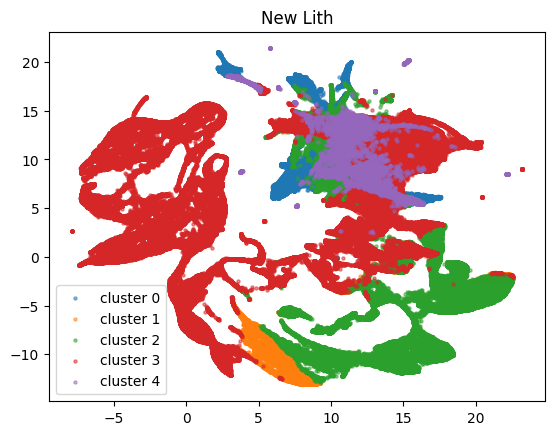

In [25]:
plot_cluster2(u,wdf.LITHCODE,title='New Lith')

In [28]:
# %load plot_cluster_set.py
def plot_cluster_set(X,ypred,clstrlst=None):
    if not clstrlst:
        clstrlst = [0]
    for c in np.unique(ypred):
        if c in clstrlst:
            plt.scatter(X[ypred==c,0],
                    X[ypred==c,1],
                        label=f'cluster {str(c)}',
                    s=5,
                        alpha=.6
                    )
    plt.legend()

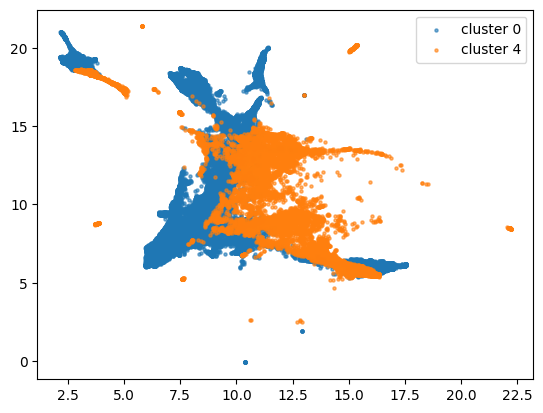

In [29]:
plot_cluster_set(u,wdf.LITHCODE,[0,4])

In [30]:
X = wdf.iloc[:,:-3]
Xssc = StandardScaler().fit_transform(X)

In [33]:
minclustersize = 500
minsamples = 10
clusterer = hdbscan.HDBSCAN(min_cluster_size=minclustersize,
            min_samples=minsamples).fit(Xssc)
# clsterdf =pd.DataFrame({colname:clusterer.labels_})
wdf1 = wdf.copy()
colname= f'DBS{minclustersize}_{minsamples}'
wdf1[colname] = clusterer.labels_
wdf1.head()


,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500_10
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,13
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,13
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,13
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,13
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,13


In [34]:
dbscan_xtab = pd.crosstab(index=wdf1.iloc[:,-3],columns=wdf1.iloc[:,-1])
dbscan_xtab

DBS500_10,-1,0,1,2,3,4,5,6,7,8,...,16,17,18,19,20,21,22,23,24,25
LITH,,,,,,,,,,,,,,,,,,,,,
Clean_Sand,13622,2044,0,0,0,1371,0,0,0,0,...,0,24,0,440,2860,2,30,0,789,6881
Dolomite,2674,18,385,0,28,0,295,55,0,10,...,0,0,0,0,0,0,93,0,0,0
Limestone,32290,1,529,17,21,24,687,450,2687,1367,...,511,38,0,606,2,62,70,0,0,379
Mudstone,66170,413,631,658,2706,0,888,0,0,0,...,0,5632,677,69,0,361,375,809,0,124
Shaly_Sand,8897,707,0,0,0,0,0,0,0,0,...,0,359,0,59,0,103,50,48,3,920


D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
D:\MLwork\WPy64-312101\python\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


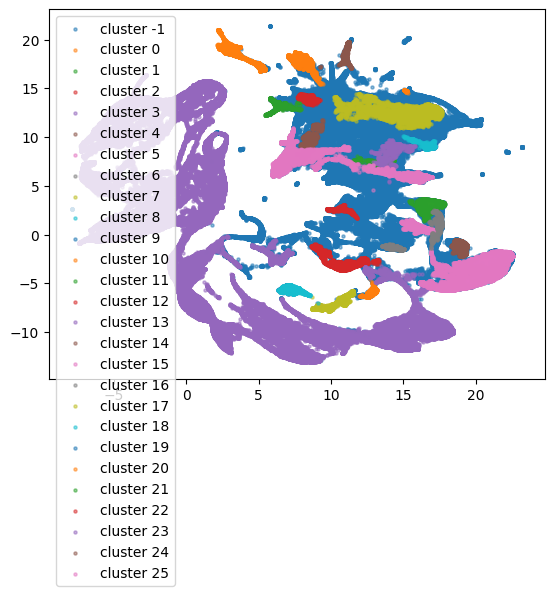

In [35]:
plot_cluster2(u,wdf1.iloc[:,-1])

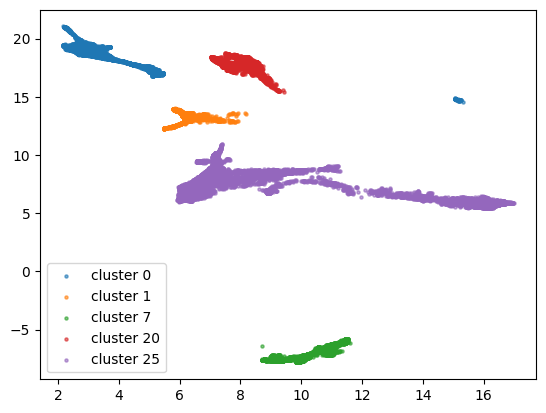

In [38]:
plot_cluster_set(u,wdf1.DBS500_10,[0,1,7,20,25])

In [39]:
wdf1.to_csv('allwellslith3DBS.csv',index=False)

Cluster evaluation without labels relies on 3 complementary internal indices:  
- silhouette score (compactness and separation)  
    -   Score of 0 indicates observation lies near cluster boundary  
- Calinski-Harabasz index  (between to within variance ratio)  
- Davies-Bouldin index: (mean worst case cluster to cluster ratio)  

No single index is definitive.  

If labels are available Adjusted Rand Index provides an external check  
that corrects for chance agreement.  
    -  Compare 2 cluster assignments, correcting for chance agreement

In [4]:
os.chdir('/media/sami/KINGSTON/NourhanPhDKhaldaData/')
os.getcwd()

'/media/sami/KINGSTON/NourhanPhDKhaldaData'

In [8]:
# wdf = pd.read_csv('allwlith3_DBS_SOM_KM_UMAP.csv')
wdf = pd.read_csv('allwlith3_DBS_SOM_KM_UMAP.csv')
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500_10,SOMX50,SOMY50,KM7,UMAP0,UMAP1
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,13,6,0,4,21.358341,14.723717
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,13,6,0,4,20.107940,15.238943
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,13,6,0,4,19.594858,15.098835
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,13,6,0,4,19.621107,15.110614
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,13,6,0,4,20.669127,15.181226


In [9]:
list(enumerate(wdf.columns))

[(0, 'DEPT'),
 (1, 'GR'),
 (2, 'PE'),
 (3, 'RHOB'),
 (4, 'RESD'),
 (5, 'NPHI'),
 (6, 'DTC'),
 (7, 'WELL'),
 (8, 'LITH'),
 (9, 'LITHCODE'),
 (10, 'DBS500_10'),
 (11, 'SOMX50'),
 (12, 'SOMY50'),
 (13, 'KM7'),
 (14, 'UMAP0'),
 (15, 'UMAP1')]

In [10]:
tsnedf = pd.read_csv('tsnep180.csv')
tsnedf.head()

,TSNE0,TSNE1
0,104.634891,-49.385360
1,106.272226,-40.304920
2,106.120451,-35.387014
3,106.184921,-35.786172
4,105.825661,-44.469067


In [11]:
wdf[['TSNE0','TSNE1']] = tsnedf.iloc[:,:].round(2) 
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500_10,SOMX50,SOMY50,KM7,UMAP0,UMAP1,TSNE0,TSNE1
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,13,6,0,4,21.358341,14.723717,104.63,-49.39
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,13,6,0,4,20.107940,15.238943,106.27,-40.30
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,13,6,0,4,19.594858,15.098835,106.12,-35.39
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,13,6,0,4,19.621107,15.110614,106.18,-35.79
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,13,6,0,4,20.669127,15.181226,105.83,-44.47


In [13]:
Xssc = StandardScaler().fit_transform(wdf.iloc[:,1:7].values)
wdf1 = wdf.copy()
pca = PCA().fit_transform(Xssc)
pca.shape

(238447, 6)

In [17]:
wdf[['PCA0','PCA1']] = pca[:,:2].round(2)
wdf.head()

,DEPT,GR,PE,RHOB,RESD,NPHI,DTC,WELL,LITH,LITHCODE,DBS500_10,SOMX50,SOMY50,KM7,UMAP0,UMAP1,TSNE0,TSNE1,PCA0,PCA1
0,200.0,18.46057,5.671854,2.291361,-0.324393,0.266411,94.928857,Berenice-11,Mudstone,3,13,6,0,4,21.358341,14.723717,104.63,-49.39,1.96,-0.94
1,200.5,20.62981,5.687283,2.292663,-0.320920,0.270630,95.637609,Berenice-11,Mudstone,3,13,6,0,4,20.107940,15.238943,106.27,-40.30,1.99,-0.85
2,201.0,21.80671,5.695586,2.293374,-0.319021,0.272916,96.021234,Berenice-11,Mudstone,3,13,6,0,4,19.594858,15.098835,106.12,-35.39,2.01,-0.81
3,201.5,21.69254,5.694617,2.293315,-0.319171,0.272687,95.981858,Berenice-11,Mudstone,3,13,6,0,4,19.621107,15.110614,106.18,-35.79,2.01,-0.81
4,202.0,19.63747,5.679710,2.292099,-0.322399,0.268675,95.306572,Berenice-11,Mudstone,3,13,6,0,4,20.669127,15.181226,105.83,-44.47,1.98,-0.89


In [18]:
list(enumerate(wdf))

[(0, 'DEPT'),
 (1, 'GR'),
 (2, 'PE'),
 (3, 'RHOB'),
 (4, 'RESD'),
 (5, 'NPHI'),
 (6, 'DTC'),
 (7, 'WELL'),
 (8, 'LITH'),
 (9, 'LITHCODE'),
 (10, 'DBS500_10'),
 (11, 'SOMX50'),
 (12, 'SOMY50'),
 (13, 'KM7'),
 (14, 'UMAP0'),
 (15, 'UMAP1'),
 (16, 'TSNE0'),
 (17, 'TSNE1'),
 (18, 'PCA0'),
 (19, 'PCA1')]

In [19]:
wdf.to_csv('allwlith3_DBS_SOM_KM_UMAP_TSNE_PCA.csv')

In [34]:
# plot selected target bin and selected clusters on umap projection
def plot_cluster_set2(
        X,
        ypred, # column of cluster numbers
        yorig, # LITHCODE
        clustrlst=None,  # of the ypred -> cluster numbers
        yoriglst=None, # LITHCODE cluster number 
        title='', 
        xlabel='',
        ylabel=''
        ):
    if not clustrlst:
        clustrlst = [0]
    fig,ax = plt.subplots()

    for c in np.unique(ypred):
        if c in clustrlst:
            ax.scatter(X[ypred==c,0],
                    X[ypred==c,1],
                        label=f'cluster {str(c)}',
                    s=1,
                        alpha=.3
                    )
    for c in np.unique(yorig):
        if c in yoriglst:
            ax.scatter(X[yorig==c,0],
                        X[yorig==c,1],
                        label=f'Lith {str(c)}',
                        s=2,
                        alpha=.3,
                        marker='^',
                        c='k'
                        )
    # ax.legend()
    # Place legend outside to the right
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0)

    ax.set_title(f'{title}')
    ax.set_xlabel(f'{xlabel}')
    ax.set_ylabel(f'{ylabel}')



In [25]:
unique,counts = np.unique(wdf.iloc[:,13].values,return_counts=True)
kmcounts = dict(zip(unique,counts))
kmcounts

{0: 40299, 1: 19969, 2: 30982, 3: 31816, 4: 77699, 5: 14051, 6: 23631}

In [41]:
lithdf = pd.crosstab(index=wdf.iloc[:,8],columns=wdf.iloc[:,9])
lithdf 

LITHCODE,0,1,2,3,4
LITH,,,,,
Clean_Sand,28063,0,0,0,0
Dolomite,0,10328,0,0,0
Limestone,0,0,62236,0,0
Mudstone,0,0,0,126674,0
Shaly_Sand,0,0,0,0,11146


In [42]:
lithdict = dict(zip(lithdf.columns,lithdf.index))
lithdict 

{0: 'Clean_Sand',
 1: 'Dolomite',
 2: 'Limestone',
 3: 'Mudstone',
 4: 'Shaly_Sand'}

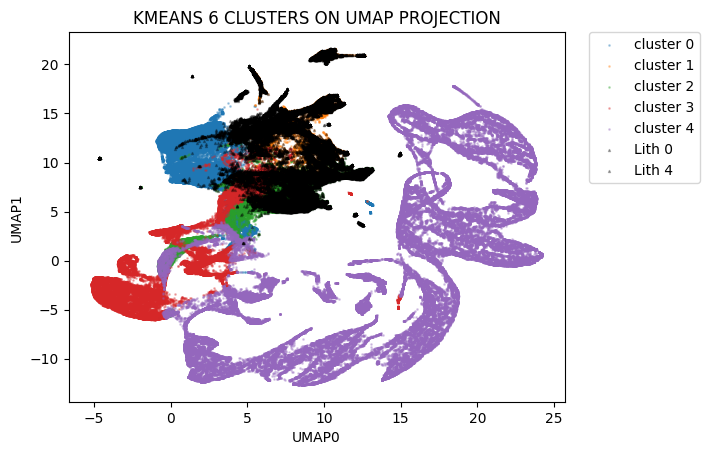

In [38]:

# Plotting on UMAP
plot_cluster_set2(
    wdf.iloc[:,14:16].values,  # umap 2D array
    wdf1.iloc[:,13].values, # KMEANS 6
    wdf1.iloc[:,9].values, #LITHCODE
    clustrlst=[0,1,2,3,4],
    # yoriglst=[0,1,2,4] plot all lithologies
    yoriglst=[0,4], # plot only clean sand and shaly sand
    # title='KMEANS 7 CLUSTERS ON UMAP PROJECTION'
    title='KMEANS 6 CLUSTERS ON UMAP PROJECTION',
    xlabel='UMAP0',
    ylabel='UMAP1'

)


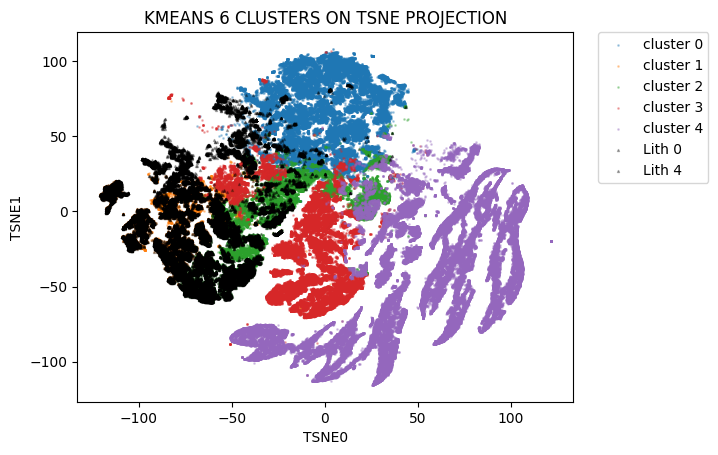

In [39]:

# Plotting on TSNE
plot_cluster_set2(
    wdf.iloc[:,16:18].values,  # umap 2D array
    wdf1.iloc[:,13].values, # KMEANS 6
    wdf1.iloc[:,9].values, #LITHCODE
    clustrlst=[0,1,2,3,4],
    # yoriglst=[0,1,2,4] plot all lithologies
    yoriglst=[0,4], # plot only clean sand and shaly sand
    # title='KMEANS 7 CLUSTERS ON UMAP PROJECTION'
    title='KMEANS 6 CLUSTERS ON TSNE PROJECTION', 
    xlabel='TSNE0',
    ylabel='TSNE1'
)


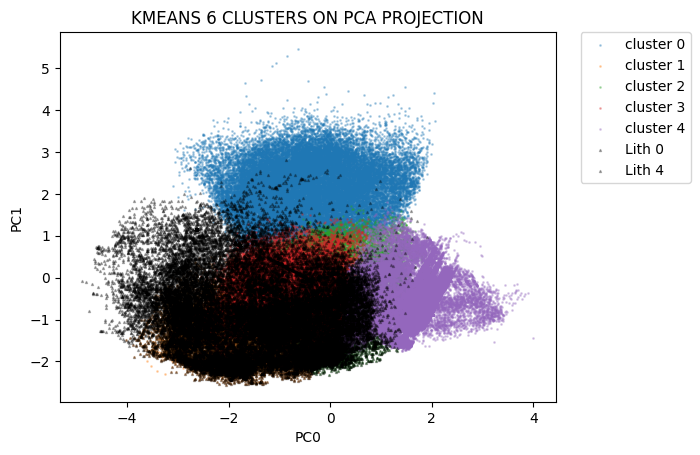

In [37]:

# Plotting on PCA
plot_cluster_set2(
    wdf.iloc[:,18:].values,  # umap 2D array
    wdf1.iloc[:,13].values, # KMEANS 6
    wdf1.iloc[:,9].values, #LITHCODE
    clustrlst=[0,1,2,3,4],
    # yoriglst=[0,1,2,4] plot all lithologies
    yoriglst=[0,4], # plot only clean sand and shaly sand
    # title='KMEANS 7 CLUSTERS ON UMAP PROJECTION'
    title='KMEANS 6 CLUSTERS ON PCA PROJECTION',
    xlabel='PC0',
    ylabel='PC1'

)


## **SOM CLUSTER SET**

In [43]:
# Used with SOM clustering
def plot_som_cluster_set3(
        X,
        yorig, # LITHCODE
        yoriglst=None, # LITHBIN 
        lithdict=None,
        title=''
        ):

    
    fig,ax = plt.subplots()

    
    for c in np.unique(yorig):
        if c in yoriglst:
            ax.scatter(X[yorig==c,0],
                        X[yorig==c,1],
                        # label=f'Lith {str(c)}',
                        label=f'Lith {lithdict[c]}',
                        s=5,
                        alpha=.3,
                        # marker='^',
                        # c='k'
                        )
    # ax.legend()
    # Place legend outside to the right
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0)

    ax.set_title(f'{title}') 
    ax.set_xlabel('SOMX')
    ax.set_ylabel('SOMY')


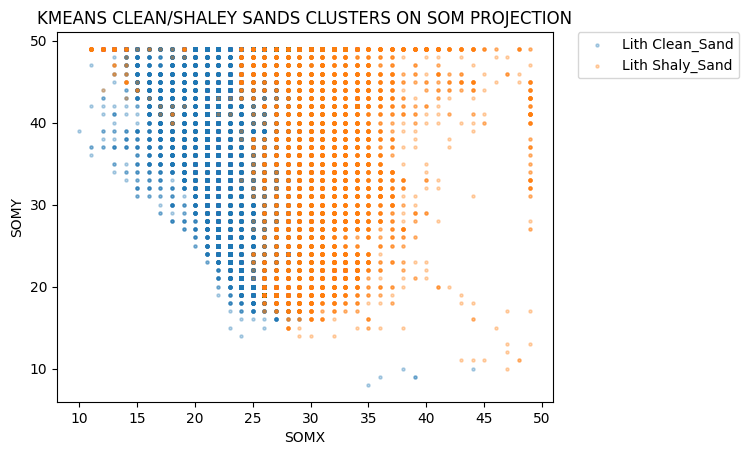

In [ ]:


# plotting KM on SOM
plot_som_cluster_set3(
    wdf1.iloc[:,[11,12]].values,
    wdf1.iloc[:,9],
    yoriglst=[0,4], # plot all lithologies
    lithdict=lithdict,
    # title='DBSCAN CLEAN SANDS CLUSTERS ON UMAP PROJECTION'
    title='KMEANS CLEAN/SHALEY SANDS CLUSTERS ON SOM PROJECTION'
    # title='KMEANS 2 CLUSTERS ON UMAP PROJECTION'
)


## **ANALYZE DBSCAN WITH LITHOLOGY**

In [45]:
list(enumerate(wdf.columns))

[(0, 'DEPT'),
 (1, 'GR'),
 (2, 'PE'),
 (3, 'RHOB'),
 (4, 'RESD'),
 (5, 'NPHI'),
 (6, 'DTC'),
 (7, 'WELL'),
 (8, 'LITH'),
 (9, 'LITHCODE'),
 (10, 'DBS500_10'),
 (11, 'SOMX50'),
 (12, 'SOMY50'),
 (13, 'KM7'),
 (14, 'UMAP0'),
 (15, 'UMAP1'),
 (16, 'TSNE0'),
 (17, 'TSNE1'),
 (18, 'PCA0'),
 (19, 'PCA1')]

In [47]:
dbsxtdf = pd.crosstab(index=wdf.iloc[:,8],columns=wdf.iloc[:,10])
dbsxtdf

DBS500_10,-1,0,1,2,3,4,5,6,7,8,...,16,17,18,19,20,21,22,23,24,25
LITH,,,,,,,,,,,,,,,,,,,,,
Clean_Sand,13622,2044,0,0,0,1371,0,0,0,0,...,0,24,0,440,2860,2,30,0,789,6881
Dolomite,2674,18,385,0,28,0,295,55,0,10,...,0,0,0,0,0,0,93,0,0,0
Limestone,32290,1,529,17,21,24,687,450,2687,1367,...,511,38,0,606,2,62,70,0,0,379
Mudstone,66170,413,631,658,2706,0,888,0,0,0,...,0,5632,677,69,0,361,375,809,0,124
Shaly_Sand,8897,707,0,0,0,0,0,0,0,0,...,0,359,0,59,0,103,50,48,3,920


In [50]:
dbsxtdf.iloc[0,:].nlargest(5)

DBS500_10
-1     13622
 25     6881
 20     2860
 0      2044
 4      1371
Name: Clean_Sand, dtype: int64

In [51]:
dbsxtdf.iloc[4,:].nlargest(5)

DBS500_10
-1     8897
 25     920
 0      707
 17     359
 21     103
Name: Shaly_Sand, dtype: int64

## **DBSCAN shows that clean sands are in clusters 25 and 20. Shaley sands are in 25 and 0**

## **You need to plot those clusters on UMAP/TSNE/PCA**